In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
or_data = pd.DataFrame()
and_data = pd.DataFrame()
xor_data = pd.DataFrame()

In [31]:
or_data['input1']=[1,1,0,0]
or_data['input2']=[1,0,1,0]
or_data['output']=[1,1,1,0]

In [32]:
and_data['input1']=[1,1,0,0]
and_data['input2']=[1,0,1,0]
and_data['output']=[1,0,0,0]

In [33]:
xor_data['input1']=[1,1,0,0]
xor_data['input2']=[1,0,1,0]
xor_data['output']=[0,1,1,0]

In [34]:
and_data

,input1,input2,output
0,1,1,1
1,1,0,0
2,0,1,0
3,0,0,0


<Axes: xlabel='input1', ylabel='input2'>

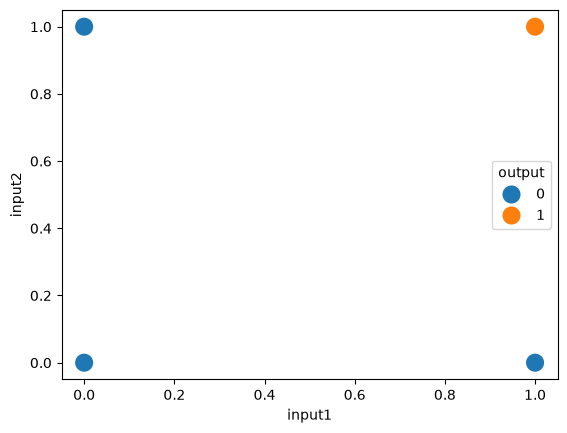

In [41]:
sns.scatterplot(
    data=and_data,
    x='input1',
    y='input2',
    hue='output',
    s=200
)

In [43]:
or_data

,input1,input2,output
0,1,1,1
1,1,0,1
2,0,1,1
3,0,0,0


<Axes: xlabel='input1', ylabel='input2'>

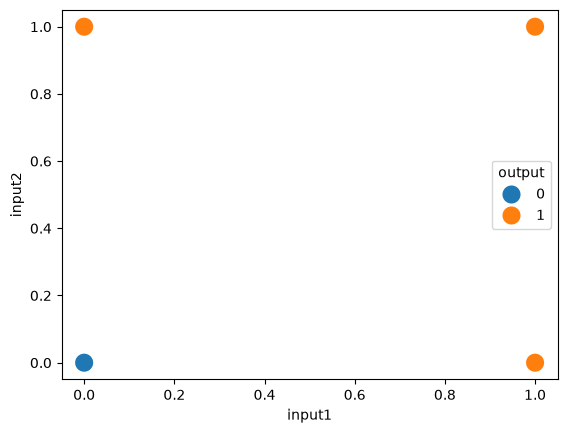

In [42]:
sns.scatterplot(
    data=or_data,
    x='input1',
    y='input2',
    hue='output',
    s=200
)

In [44]:
xor_data

,input1,input2,output
0,1,1,0
1,1,0,1
2,0,1,1
3,0,0,0


<Axes: xlabel='input1', ylabel='input2'>

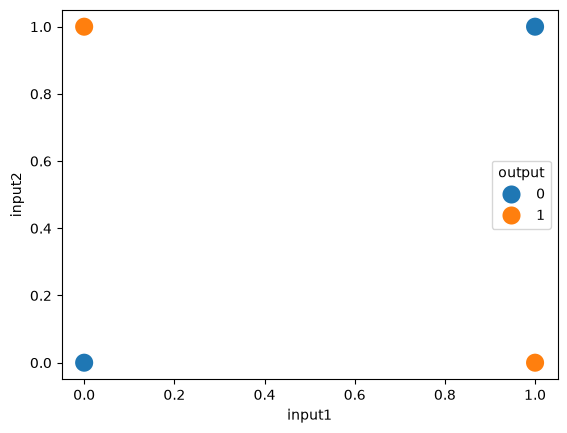

In [45]:
sns.scatterplot(
    data=xor_data,
    x='input1',
    y='input2',
    hue='output',
    s=200
)

In [46]:
from sklearn.linear_model import Perceptron
clf1=Perceptron()
clf2=Perceptron()
clf3=Perceptron()

In [47]:
clf1.fit(and_data.iloc[:,0:2].values,and_data.iloc[:,-1].values)
clf2.fit(or_data.iloc[:,0:2].values,or_data.iloc[:,-1].values)
clf3.fit(xor_data.iloc[:,0:2].values,xor_data.iloc[:,-1].values)

,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",0


In [48]:
clf1.coef_

array([[2., 2.]])

In [49]:
clf1.intercept_

array([-2.])

In [50]:
x=np.linspace(-1,1,5)
y = -x + 1

<Axes: xlabel='input1', ylabel='input2'>

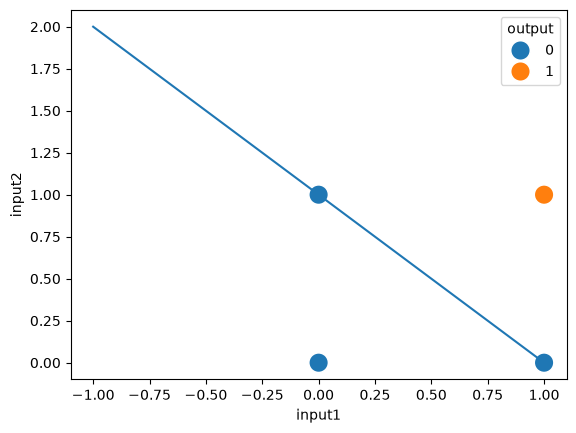

In [52]:
plt.plot(x,y)
sns.scatterplot(
    data=and_data,
    x='input1',
    y='input2',
    hue='output',
    s=200
)

In [53]:
clf2.coef_

array([[2., 2.]])

In [54]:
clf2.intercept_

array([-1.])

In [56]:
x1 = np.linspace(-1,1,5)
y1 = -x + 0.5

<Axes: xlabel='input1', ylabel='input2'>

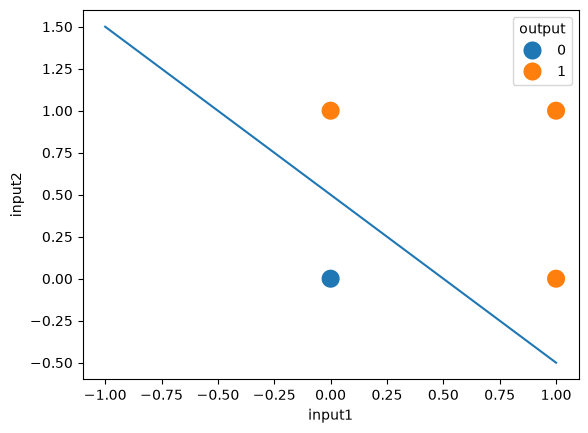

In [57]:
plt.plot(x1, y1)
sns.scatterplot(
    data=or_data,
    x='input1',
    y='input2',
    hue='output',
    s=200
)

In [58]:
clf3.coef_

array([[0., 0.]])

In [59]:
clf3.intercept_

array([0.])

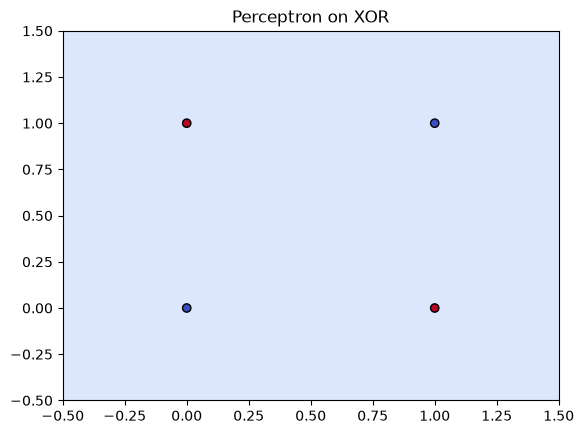

In [64]:
import numpy as np

import matplotlib.pyplot as plt

def plot_decision_regions(X, y, clf, legend=2):
    X = np.asarray(X)
    y = np.asarray(y)

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.title("Perceptron on XOR")
    plt.show()

plot_decision_regions(
    xor_data.iloc[:, 0:2].values,
    xor_data.iloc[:, -1].values,
    clf=clf3,
    legend=2
)